# Sampling

In [1]:
# datascience
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

In [2]:
# polars
import polars as pl
from IPython.display import display
import numpy as np

def _append(base, extra):
    """Append a value or a Series onto a Series."""
    extra_s = extra if isinstance(extra, pl.Series) else pl.Series([extra])
    if base.len() == 0:
        return extra_s
    if base.dtype != extra_s.dtype:
        try:
            extra_s = extra_s.cast(base.dtype, strict=False)
        except Exception:
            base = base.cast(extra_s.dtype, strict=False)
    return pl.concat([base, extra_s])


## Random Sampling ##

We load in a dataset of all United flights national flights from 6/1/15 to 8/9/15, their destination and how long they were delayed, in minutes.

In [3]:
# datascience
united = Table.read_table('united.csv')
united = united.with_column('Row', np.arange(united.num_rows)).move_to_start('Row')
united

Row,Date,Flight Number,Destination,Delay
0,6/1/15,73,HNL,257
1,6/1/15,217,EWR,28
2,6/1/15,237,STL,-3
3,6/1/15,250,SAN,0
4,6/1/15,267,PHL,64
5,6/1/15,273,SEA,-6
6,6/1/15,278,SEA,-8
7,6/1/15,292,EWR,12
8,6/1/15,300,HNL,20
9,6/1/15,317,IND,-10


In [4]:
# polars
united_pl = pl.read_csv('united.csv', eol_char='\r')
united_pl = (lambda _df, _c='Row': _df.select([_c] + [c for c in _df.columns if c != _c]))(united_pl.with_columns(pl.Series('Row', pl.int_range(united_pl.height, eager=True))))
united_pl

Row,Date,Flight Number,Destination,Delay
i64,str,i64,str,i64
0,"""6/1/15""",73,"""HNL""",257
1,"""6/1/15""",217,"""EWR""",28
2,"""6/1/15""",237,"""STL""",-3
3,"""6/1/15""",250,"""SAN""",0
4,"""6/1/15""",267,"""PHL""",64
…,…,…,…,…
13820,"""8/31/15""",1978,"""LAS""",-4
13821,"""8/31/15""",1993,"""IAD""",8
13822,"""8/31/15""",1994,"""ORD""",3


Some deterministic samples:

In [5]:
# datascience
united.where('Destination', 'JFK') 

Row,Date,Flight Number,Destination,Delay
26,6/1/15,502,JFK,-4
33,6/1/15,637,JFK,141
39,6/1/15,704,JFK,-8
50,6/1/15,758,JFK,-5
51,6/1/15,760,JFK,352
56,6/1/15,824,JFK,3
57,6/1/15,898,JFK,290
179,6/2/15,502,JFK,0
188,6/2/15,637,JFK,202
194,6/2/15,704,JFK,-11


In [6]:
# polars
united_pl.filter(pl.col('Destination') == 'JFK') 

Row,Date,Flight Number,Destination,Delay
i64,str,i64,str,i64
26,"""6/1/15""",502,"""JFK""",-4
33,"""6/1/15""",637,"""JFK""",141
39,"""6/1/15""",704,"""JFK""",-8
50,"""6/1/15""",758,"""JFK""",-5
51,"""6/1/15""",760,"""JFK""",352
…,…,…,…,…
13716,"""8/31/15""",704,"""JFK""",9
13720,"""8/31/15""",758,"""JFK""",-2
13721,"""8/31/15""",760,"""JFK""",-5


In [7]:
# datascience
united.take(np.arange(0, united.num_rows, 1000))

Row,Date,Flight Number,Destination,Delay
0,6/1/15,73,HNL,257
1000,6/7/15,1692,EWR,7
2000,6/14/15,824,JFK,-1
3000,6/21/15,217,EWR,5
4000,6/27/15,1401,SAN,-4
5000,7/4/15,1614,LAS,-2
6000,7/11/15,401,CLE,4
7000,7/17/15,1645,IAD,0
8000,7/24/15,624,ORD,61
9000,7/30/15,1728,ORD,209


In [8]:
# polars
united_pl.gather(pl.int_range(0, united_pl.height, 1000, eager=True))

Row,Date,Flight Number,Destination,Delay
i64,str,i64,str,i64
0,"""6/1/15""",73,"""HNL""",257
1000,"""6/7/15""",1692,"""EWR""",7
2000,"""6/14/15""",824,"""JFK""",-1
3000,"""6/21/15""",217,"""EWR""",5
4000,"""6/27/15""",1401,"""SAN""",-4
…,…,…,…,…
9000,"""7/30/15""",1728,"""ORD""",209
10000,"""8/6/15""",620,"""ORD""",-4
11000,"""8/12/15""",1608,"""EWR""",-4


In [9]:
# datascience
united.take(make_array(34, 6321, 10040))

Row,Date,Flight Number,Destination,Delay
34,6/1/15,650,AUS,44
6321,7/13/15,1124,SEA,-7
10040,8/6/15,1216,LAS,2


In [10]:
# polars
united_pl.gather(pl.Series("values", [34, 6321, 10040]))

Row,Date,Flight Number,Destination,Delay
i64,str,i64,str,i64
34,"""6/1/15""",650,"""AUS""",44
6321,"""7/13/15""",1124,"""SEA""",-7
10040,"""8/6/15""",1216,"""LAS""",2


Random samples:

In [11]:
# datascience
united.sample(5, with_replacement=False).sort('Row')

Row,Date,Flight Number,Destination,Delay
6861,7/16/15,1754,EWR,6
8386,7/26/15,1975,FLL,21
12257,8/20/15,1960,LAX,13
12281,8/21/15,477,DFW,76
13640,8/30/15,1644,IAH,-8


In [12]:
# polars
(united_pl).sample(n=5, with_replacement=False, shuffle=True).sort('Row')

Row,Date,Flight Number,Destination,Delay
i64,str,i64,str,i64
6340,"""7/13/15""",1415,"""PDX""",-5
9033,"""7/31/15""",237,"""STL""",26
11216,"""8/14/15""",73,"""HNL""",18
13136,"""8/27/15""",497,"""SLC""",-5
13568,"""8/30/15""",602,"""SAN""",-13


In [13]:
# datascience
rows = np.random.choice(np.arange(united.num_rows), 5, replace=False)
united.take(rows).sort('Row')

Row,Date,Flight Number,Destination,Delay
3761,6/25/15,1946,BOS,3
4851,7/3/15,624,ORD,-6
6274,7/13/15,480,PIT,-9
8058,7/24/15,1517,SAN,14
10220,8/7/15,1449,LAS,-2


In [14]:
# polars
rows_pl = (pl.int_range(united_pl.height, eager=True)).sample(5, with_replacement=False)
united_pl.gather(rows_pl).sort('Row')

Row,Date,Flight Number,Destination,Delay
i64,str,i64,str,i64
2458,"""6/17/15""",816,"""LAX""",39
3950,"""6/27/15""",390,"""ORD""",10
5520,"""7/8/15""",498,"""SAN""",-4
6448,"""7/14/15""",614,"""SNA""",26
13015,"""8/26/15""",834,"""DEN""",17


In [15]:
# datascience
start = np.random.choice(np.arange(1000))
systematic_sample = united.take(np.arange(start, united.num_rows, 1000))
systematic_sample.show()

Row,Date,Flight Number,Destination,Delay
130,6/1/15,1686,DCA,32
1130,6/8/15,1526,DEN,-3
2130,6/15/15,611,SEA,-2
3130,6/21/15,1928,ORD,39
4130,6/28/15,1185,EWR,13
5130,7/5/15,1591,ORD,10
6130,7/12/15,480,PIT,-2
7130,7/18/15,1579,LAX,41
8130,7/25/15,300,HNL,41
9130,7/31/15,1517,SAN,9


In [16]:
# polars
start_pl = (pl.int_range(1000, eager=True)).sample(1).item()
systematic_sample_pl = united_pl.gather(pl.int_range(start_pl, united_pl.height, 1000, eager=True))
with pl.Config(tbl_rows=-1):
    display(systematic_sample_pl)

Row,Date,Flight Number,Destination,Delay
i64,str,i64,str,i64
804,"""6/6/15""",734,"""ORD""",-1
1804,"""6/12/15""",1928,"""ORD""",0
2804,"""6/19/15""",1273,"""OGG""",2
3804,"""6/26/15""",500,"""ORD""",70
4804,"""7/2/15""",1946,"""BOS""",10
…,…,…,…,…
9804,"""8/5/15""",318,"""DEN""",39
10804,"""8/11/15""",1124,"""SEA""",-5
11804,"""8/17/15""",1900,"""PHL""",2


## Distributions ##

In [17]:
# datascience
die = Table().with_column('Face', np.arange(1, 7))
die

Face
1
2
3
4
5
6


In [18]:
# polars
die_pl = pl.DataFrame({'Face': pl.int_range(1, 7, eager=True)})
die_pl

Face
i64
1
2
3
4
5
6


In [19]:
# datascience
die.sample(10)

Face
3
4
1
3
1
6
5
1
1
6


In [20]:
# polars
(die_pl).sample(n=10, with_replacement=True, shuffle=True)

Face
i64
1
3
3
1
4
1
3
5
4


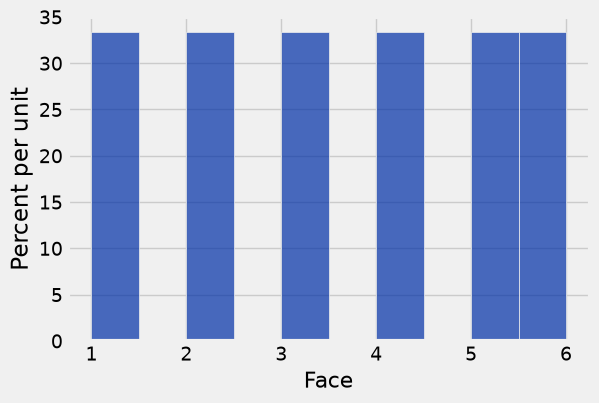

In [21]:
# datascience
die.hist('Face')

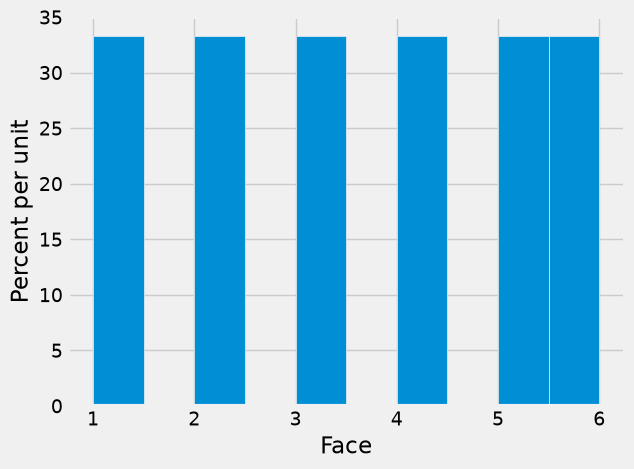

In [22]:
# polars
# matplotlib
_df = die_pl
plots.hist(_df.get_column('Face').to_numpy(), density=True)
plots.xlabel('Face')
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

In [23]:
# datascience
roll_bins = np.arange(0.5, 6.6, 1)

In [24]:
# polars
roll_bins_pl = pl.linear_space(0.5, 6.5, 7, closed="both", eager=True)

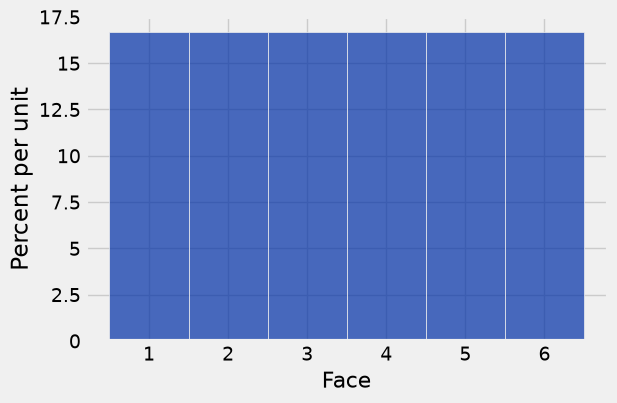

In [25]:
# datascience
die.hist('Face', bins=roll_bins)

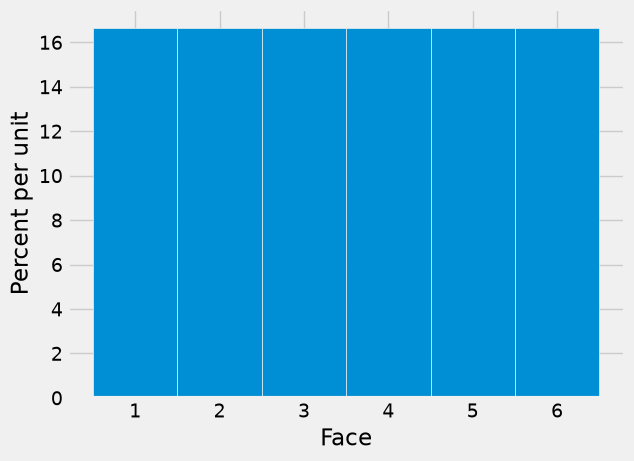

In [26]:
# polars
# matplotlib
_df = die_pl
plots.hist(_df.get_column('Face').to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(roll_bins_pl))
plots.xlabel('Face')
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

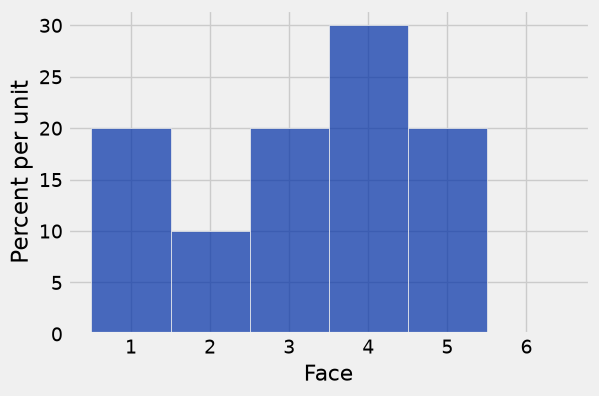

In [27]:
# datascience
die.sample(10).hist('Face', bins=roll_bins)

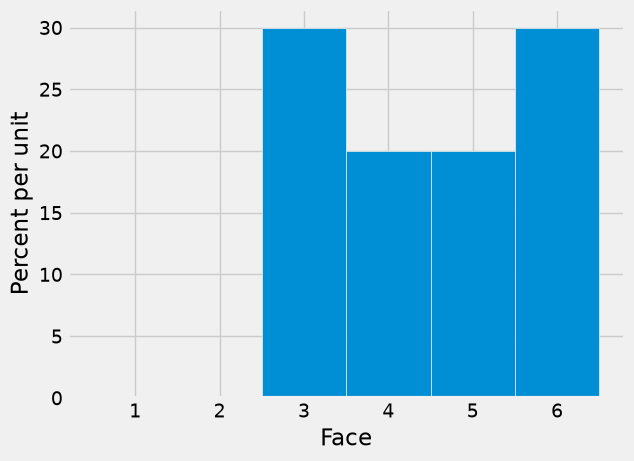

In [28]:
# polars
# matplotlib
_df = (die_pl).sample(n=10, with_replacement=True, shuffle=True)
plots.hist(_df.get_column('Face').to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(roll_bins_pl))
plots.xlabel('Face')
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

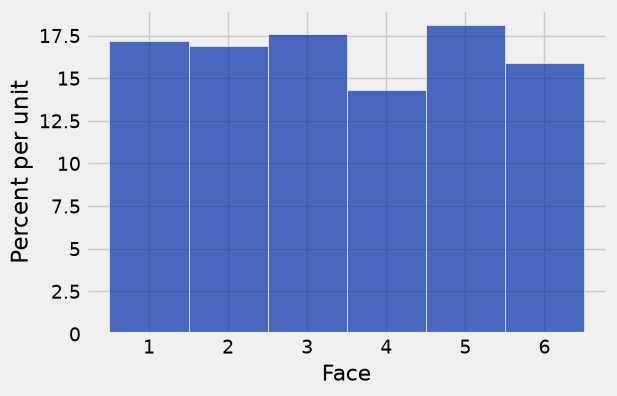

In [29]:
# datascience
die.sample(1000).hist('Face', bins=roll_bins)

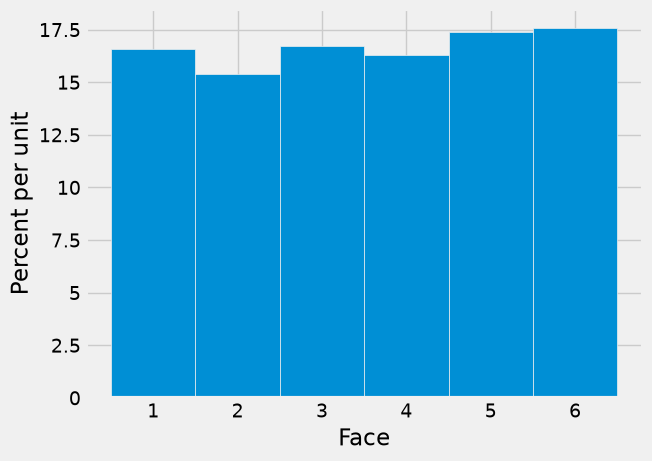

In [30]:
# polars
# matplotlib
_df = (die_pl).sample(n=1000, with_replacement=True, shuffle=True)
plots.hist(_df.get_column('Face').to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(roll_bins_pl))
plots.xlabel('Face')
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

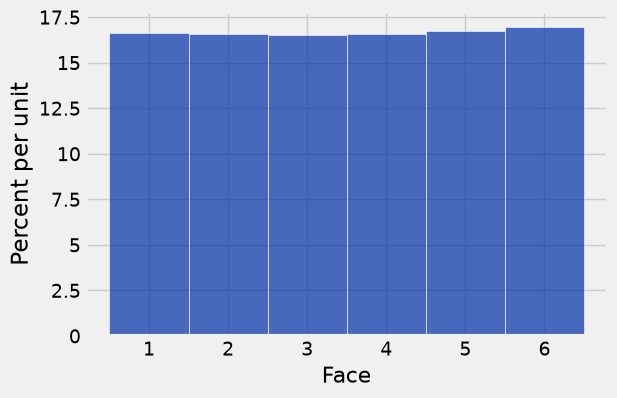

In [31]:
# datascience
die.sample(100000).hist('Face', bins=roll_bins)

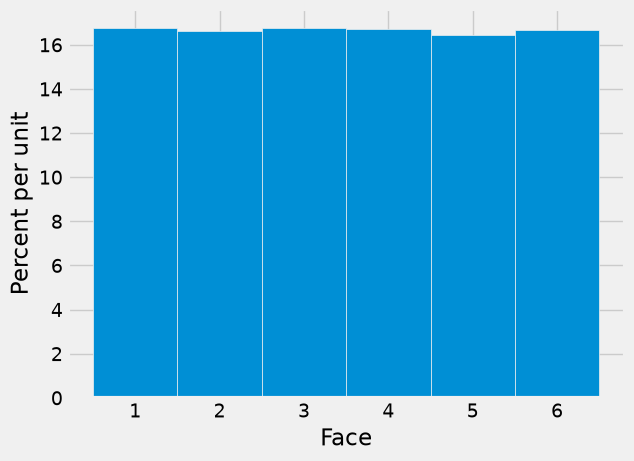

In [32]:
# polars
# matplotlib
_df = (die_pl).sample(n=100000, with_replacement=True, shuffle=True)
plots.hist(_df.get_column('Face').to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(roll_bins_pl))
plots.xlabel('Face')
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

## Large Random Samples ##

In [33]:
# datascience
united 

Row,Date,Flight Number,Destination,Delay
0,6/1/15,73,HNL,257
1,6/1/15,217,EWR,28
2,6/1/15,237,STL,-3
3,6/1/15,250,SAN,0
4,6/1/15,267,PHL,64
5,6/1/15,273,SEA,-6
6,6/1/15,278,SEA,-8
7,6/1/15,292,EWR,12
8,6/1/15,300,HNL,20
9,6/1/15,317,IND,-10


In [34]:
# polars
united_pl 

Row,Date,Flight Number,Destination,Delay
i64,str,i64,str,i64
0,"""6/1/15""",73,"""HNL""",257
1,"""6/1/15""",217,"""EWR""",28
2,"""6/1/15""",237,"""STL""",-3
3,"""6/1/15""",250,"""SAN""",0
4,"""6/1/15""",267,"""PHL""",64
…,…,…,…,…
13820,"""8/31/15""",1978,"""LAS""",-4
13821,"""8/31/15""",1993,"""IAD""",8
13822,"""8/31/15""",1994,"""ORD""",3


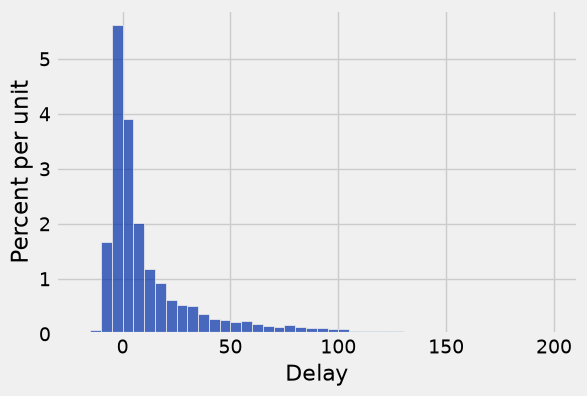

In [35]:
# datascience
united_bins = np.arange(-20, 201, 5)
united.hist('Delay', bins = united_bins)

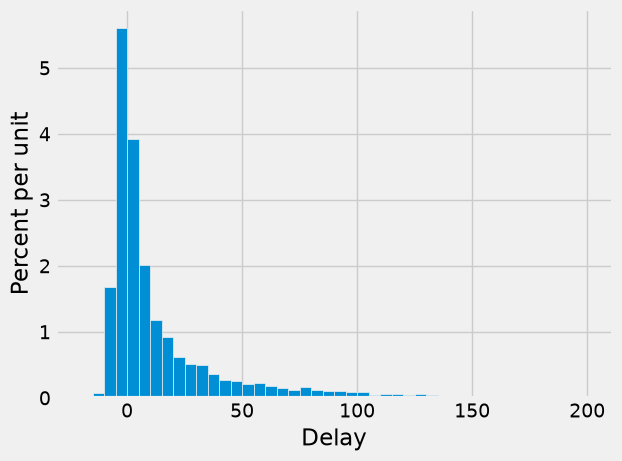

In [36]:
# polars
# matplotlib
united_bins_pl = pl.int_range(-20, 201, 5, eager=True)
_df = united_pl
plots.hist(_df.get_column('Delay').to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(united_bins_pl))
plots.xlabel('Delay')
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

In [37]:
# datascience
min(united.column('Delay'))

-16

In [38]:
# polars
min(united_pl.get_column('Delay'))

-16

In [39]:
# datascience
max(united.column('Delay'))

580

In [40]:
# polars
max(united_pl.get_column('Delay'))

580

In [41]:
# datascience
np.average(united.column('Delay'))

16.658155515370705

In [42]:
# polars
(united_pl.get_column('Delay')).mean()

16.658155515370705

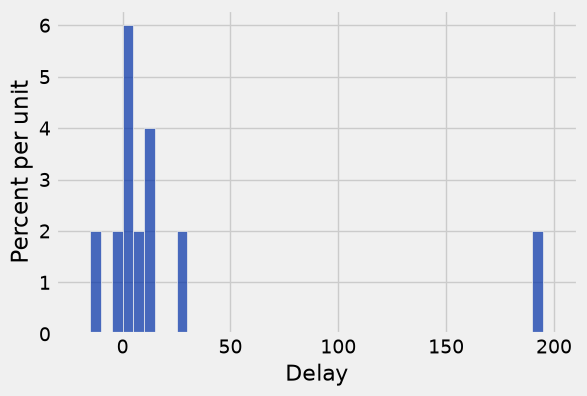

In [43]:
# datascience
united.sample(10).hist('Delay', bins = united_bins)

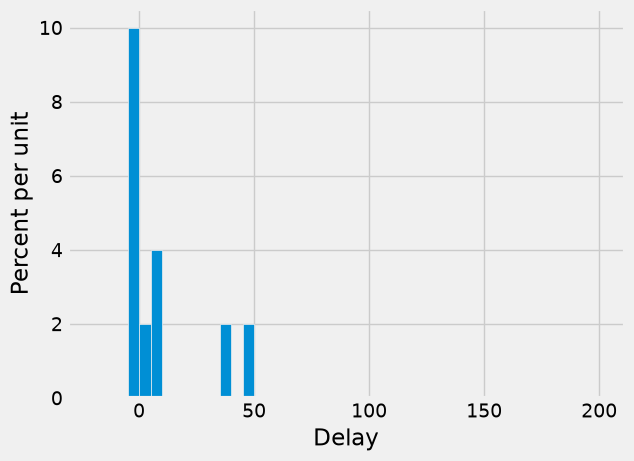

In [44]:
# polars
# matplotlib
_df = (united_pl).sample(n=10, with_replacement=True, shuffle=True)
plots.hist(_df.get_column('Delay').to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(united_bins_pl))
plots.xlabel('Delay')
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

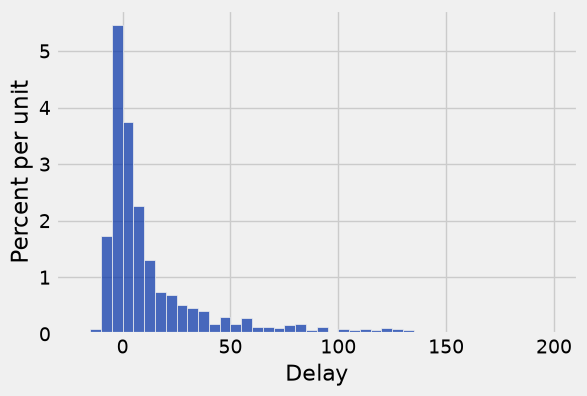

In [45]:
# datascience
united.sample(1000).hist('Delay', bins = united_bins)

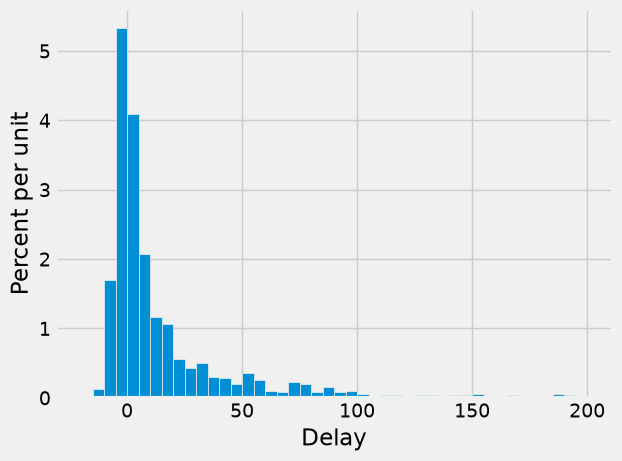

In [46]:
# polars
# matplotlib
_df = (united_pl).sample(n=1000, with_replacement=True, shuffle=True)
plots.hist(_df.get_column('Delay').to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(united_bins_pl))
plots.xlabel('Delay')
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

## Simulating Statistics ##

In [47]:
# datascience
np.median(united.column('Delay'))

2.0

In [48]:
# polars
(united_pl.get_column('Delay')).median()

2.0

In [49]:
# datascience
np.median(united.sample(10).column('Delay'))

10.0

In [50]:
# polars
((united_pl).sample(n=10, with_replacement=True, shuffle=True).get_column('Delay')).median()

-1.5

In [51]:
# datascience
def sample_median(size):
    return np.median(united.sample(size).column('Delay'))

In [52]:
# polars
def sample_median_pl(size):
    return ((united_pl).sample(n=size, with_replacement=True, shuffle=True).get_column('Delay')).median()

In [53]:
# datascience
sample_median(10)

-0.5

In [54]:
# polars
sample_median_pl(10)

1.0

In [55]:
# datascience
sample_medians = make_array()

for i in np.arange(1000):
    new_median = sample_median(10)
    sample_medians = np.append(sample_medians, new_median)

In [56]:
# polars
sample_medians_pl = []

for i in pl.int_range(1000, eager=True):
    new_median = sample_median_pl(10)
    sample_medians_pl.append(new_median)
sample_medians_pl = pl.Series("values", sample_medians_pl)

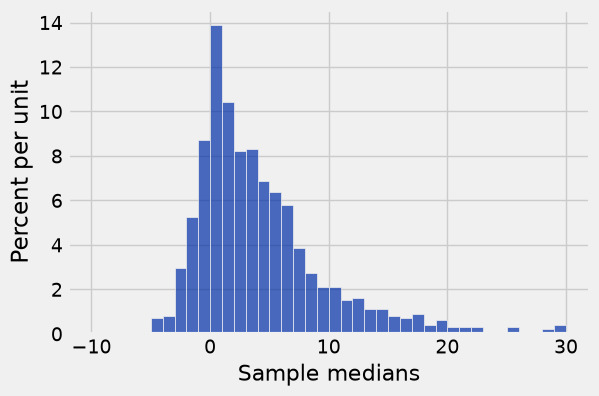

In [57]:
# datascience
Table().with_column('Sample medians', sample_medians).hist(bins = np.arange(-10,31))

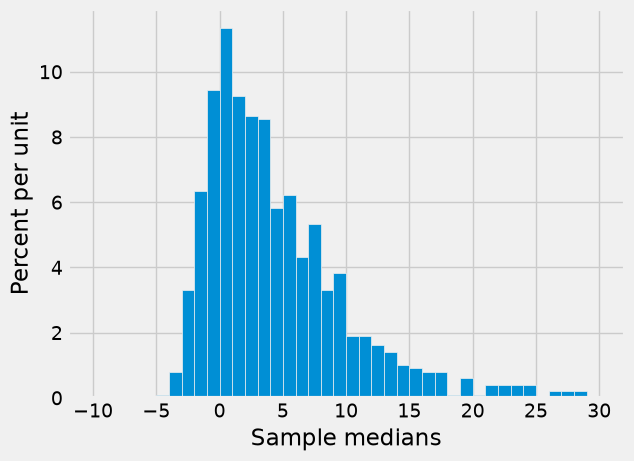

In [58]:
# polars
# matplotlib
_df = pl.DataFrame({'Sample medians': sample_medians_pl})
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.int_range(-10, 31, eager=True)))
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.int_range(-10, 31, eager=True)))
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

In [59]:
# datascience
sample_medians = make_array()

for i in np.arange(1000):
    new_median = sample_median(1000)
    sample_medians = np.append(sample_medians, new_median)

In [60]:
# polars
sample_medians_pl = []

for i in pl.int_range(1000, eager=True):
    new_median = sample_median_pl(1000)
    sample_medians_pl.append(new_median)
sample_medians_pl = pl.Series("values", sample_medians_pl)

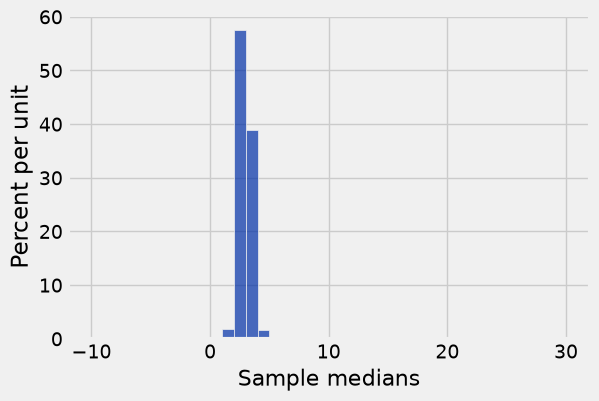

In [61]:
# datascience
Table().with_column(
    'Sample medians', sample_medians).hist(bins = np.arange(-10,31))

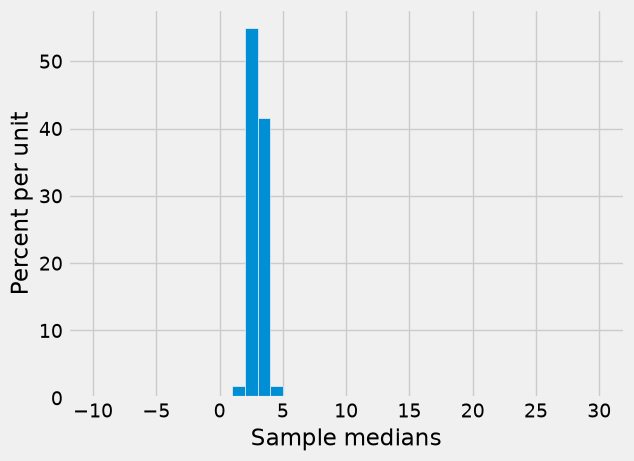

In [62]:
# polars
# matplotlib
_df = pl.DataFrame({'Sample medians': sample_medians_pl})
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.int_range(-10, 31, eager=True)))
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.int_range(-10, 31, eager=True)))
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))